Initializing and scaling data

(100, 1) (100,)


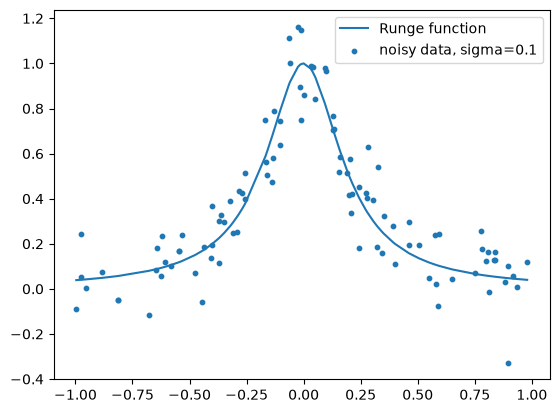

In [35]:
# The data of project 1, as a starting point for part b)
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp  
from sklearn.model_selection import train_test_split
from neural_network_functions import *
import seaborn as sns

def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)      # fix the seed for reproducible results
n = 100
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1
y = runge(x) + rng.normal(0.0, sigma, n)

# For the network the input is the raw x (one feature), samples in rows
X = x.reshape(-1, 1)
print(X.shape, y.shape)
plt.plot(x, runge(x), label="Runge function")
plt.scatter(x, y, s=10, label=f"noisy data, sigma={sigma}")
plt.legend(); plt.show()

X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)  # Standardize the input features
y_scaled = (y - y.mean()) / y.std()  # Standardize the target variable

Yrunge = runge(X.flatten())
Yrunge_scaled = (Yrunge - Yrunge.mean()) / Yrunge.std()  # Standardize the Runge function values

In [4]:
epochs = 1000
t0 = 1.0
t1 = 100.0
batch_size = 10

Xtrain, Xtest, ytrain, ytest = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)

input_size = 1
layer_output_sizes = [50, 1]
layers_one_hidden_layer = create_layers(input_size, layer_output_sizes)
layers_one_hidden_layer = train_sgd_adam(
    Xtrain = Xtrain,
    Ytrain = ytrain.reshape(-1, 1),
    layers = layers_one_hidden_layer,
    activation_funcs = [sigmoid, lambda z: z],  # Last layer is linear
    activation_ders = [sigmoid_der, lambda z: np.ones_like(z)],
    epochs = epochs,
    batch_size = batch_size,
    gamma = 0.01,
    use_decaying_step_length = True,
    t0 = t0,
    t1 = t1  
)


In [5]:
epochs = 1000
t0 = 1.0
t1 = 100.0
batch_size = 10

Xtrain, Xtest, ytrain, ytest = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)

input_size = 1
layer_output_sizes = [50,50, 1]
layers_two_hidden_layer = create_layers(input_size, layer_output_sizes)
layers_two_hidden_layer = train_sgd_adam(
    Xtrain = Xtrain,
    Ytrain = ytrain.reshape(-1, 1),
    layers = layers_two_hidden_layer,
    activation_funcs = [sigmoid, sigmoid, lambda z: z],  # Last layer is linear
    activation_ders = [sigmoid_der, sigmoid_der, lambda z: np.ones_like(z)],
    epochs = epochs,
    batch_size = batch_size,
    gamma = 0.01,
    use_decaying_step_length = True,
    t0 = t0,
    t1 = t1  
)


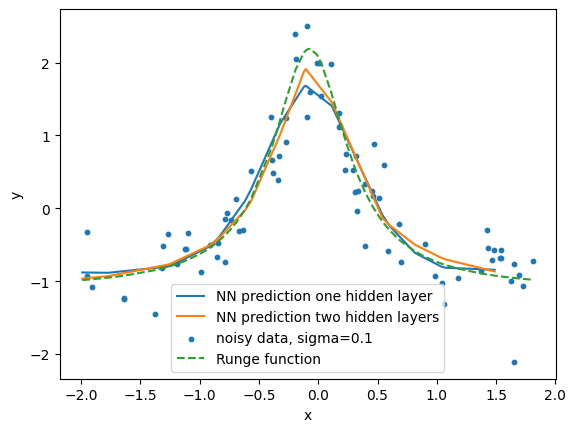

In [6]:
y_pred_one_hidden_layers = feed_forward(Xtest, layers_one_hidden_layer, [sigmoid, lambda z: z])
y_pred_two_hidden_layers = feed_forward(Xtest, layers_two_hidden_layer, [sigmoid, sigmoid, lambda z: z])
sort_idx = np.argsort(Xtest.flatten()) #<- Chatgpt la til fix

plt.plot(Xtest[sort_idx], y_pred_one_hidden_layers[sort_idx], label="NN prediction one hidden layer")
plt.plot(Xtest[sort_idx], y_pred_two_hidden_layers[sort_idx], label="NN prediction two hidden layers")

plt.scatter(Xtrain, ytrain, s=10, label=f"noisy data, sigma={sigma}")
plt.plot(X_scaled, Yrunge_scaled, label="Runge function", linestyle="--")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

In [30]:
MSE_one_hidden = np.mean((y_pred_one_hidden_layers.flatten() - ytest)**2)
print(f"MSE for one hidden layer: {MSE_one_hidden}")

MSE_two_hidden = np.mean((y_pred_two_hidden_layers.flatten() - ytest)**2)
print(f"MSE for two hidden layers: {MSE_two_hidden}")

MSE for one hidden layer: 0.16415882110595703
MSE for two hidden layers: 0.1383737027645111


In [28]:
epochs = 1000
t0 = 1.0
t1 = 100.0
batch_size = 10

Xtrain, Xtest, ytrain, ytest = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)

input_size = 1
layer_output_sizes = [50, 1]
layers_adam = create_layers(input_size, layer_output_sizes)
layers_adam = train_sgd_adam(
    Xtrain = Xtrain,
    Ytrain = ytrain.reshape(-1, 1),
    layers = layers_adam,
    activation_funcs = [sigmoid, lambda z: z],  # Last layer is linear
    activation_ders = [sigmoid_der, lambda z: np.ones_like(z)],
    epochs = epochs,
    batch_size = batch_size,
    gamma = 0.01,
    use_decaying_step_length = True,
    t0 = t0,
    t1 = t1  
)

layers_plain = create_layers(input_size, layer_output_sizes)
layers_plain = train_sgd_plain(
    Xtrain = Xtrain,
    Ytrain = ytrain.reshape(-1, 1),
    layers = layers_plain,
    activation_funcs = [sigmoid, lambda z: z],  # Last layer is linear
    activation_ders = [sigmoid_der, lambda z: np.ones_like(z)],
    epochs = epochs,
    batch_size = batch_size,
    gamma = 0.01,
    use_decaying_step_length = True,
    t0 = t0,
    t1 = t1  
)

layers_RMSprop = create_layers(input_size, layer_output_sizes)
layers_RMSprop = train_sgd_RMSprop(
    Xtrain = Xtrain,
    Ytrain = ytrain.reshape(-1, 1),
    layers = layers_RMSprop,
    activation_funcs = [sigmoid, lambda z: z],  # Last layer is linear
    activation_ders = [sigmoid_der, lambda z: np.ones_like(z)],
    epochs = epochs,
    batch_size = batch_size,
    gamma = 0.01,
    use_decaying_step_length = True,
    t0 = t0,
    t1 = t1  
)

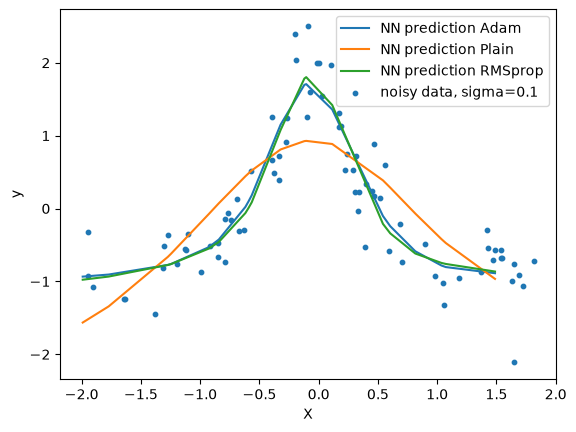

In [29]:
y_pred_adam = feed_forward(Xtest, layers_adam, [sigmoid, lambda z: z])
y_pred_plain = feed_forward(Xtest, layers_plain, [sigmoid, lambda z: z])
y_pred_RMSprop = feed_forward(Xtest, layers_RMSprop, [sigmoid, lambda z: z])

sort_idx = np.argsort(Xtest.flatten()) 

plt.plot(Xtest[sort_idx], y_pred_adam[sort_idx], label="NN prediction Adam")
plt.plot(Xtest[sort_idx], y_pred_plain[sort_idx], label="NN prediction Plain")
plt.plot(Xtest[sort_idx], y_pred_RMSprop[sort_idx], label="NN prediction RMSprop")
plt.scatter(Xtrain, ytrain, s=10, label=f"noisy data, sigma={sigma}")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()


In [31]:
MSE_plain = np.mean((y_pred_plain.flatten() - ytest)**2)
MSE_adam = np.mean((y_pred_adam.flatten() - ytest)**2)
MSE_RMSprop = np.mean((y_pred_RMSprop.flatten() - ytest)**2)
print(f"MSE for plain SGD: {MSE_plain}")
print(f"MSE for Adam: {MSE_adam}")
print(f"MSE for RMSprop: {MSE_RMSprop}")

MSE for plain SGD: 0.38881516456604004
MSE for Adam: 0.15211397409439087
MSE for RMSprop: 0.14480939507484436


In [23]:
cost_grad = jax.grad(cost, argnums=0)

layers = create_layers(1,[50, 1])

layer_grads = backpropagation(Xtrain, layers, [sigmoid, lambda z: z], target = ytrain.reshape(-1,1), activation_ders = [sigmoid_der, lambda z: np.ones_like(z)])

cost_grad = jax.grad(cost, argnums=0)
layer_grads_jax = cost_grad(layers, Xtrain, [sigmoid, lambda z: z], ytrain.reshape(-1, 1))
#print(layer_grads_jax)

# the check: every dW and db agrees with JAX to machine precision
print([ (np.allclose(dW, dW_j), np.allclose(db, db_j))
        for (dW, db), (dW_j, db_j) in zip(layer_grads, layer_grads_jax) ])

[(True, True), (True, True)]


In [42]:
#c
#ikke kjør på nytt. tar lang tid.
functions = [ReLU, leaky_ReLU, sigmoid]
functions_der = [ReLU_der, leaky_ReLU_der, sigmoid_der]
number_of_nodes = np.arange(2,10,2)  # Example range of nodes
number_of_hidden_layers = np.arange(1, 4)  # Example range of hidden layers

layer_output_sizes = [50, 1]  # Example layer sizes for the network
layer_input_size = 1  # Input size for the network

epochs = 1000
t0 = 1.0
t1 = 100.0
batch_size = 10

MSEs = np.zeros((len(functions), len(number_of_hidden_layers), len(number_of_nodes)))  # Initialize MSE array for all functions


for k, (function, function_der) in enumerate(zip(functions, functions_der)):
    for i, n_layers in enumerate(number_of_hidden_layers):
        for j, n_nodes in enumerate(number_of_nodes):
            layers = create_layers(layer_input_size, layer_output_sizes)
            layers = train_sgd_adam(
                Xtrain=Xtrain,
                Ytrain=ytrain.reshape(-1, 1),
                layers=layers,
                activation_funcs=[function] * n_layers + [lambda z: z],  # Last layer is linear
                activation_ders=[function_der] * n_layers + [lambda z: np.ones_like(z)],
                epochs=epochs,
                batch_size=batch_size,
                gamma=0.01,
                use_decaying_step_length=True,
                t0=t0,
                t1=t1
            )
            y_pred = feed_forward(Xtest, layers, [function] * n_layers + [lambda z: z])
            MSEs[k, i, j] = np.mean((y_pred - ytest.reshape(-1, 1))**2)
            


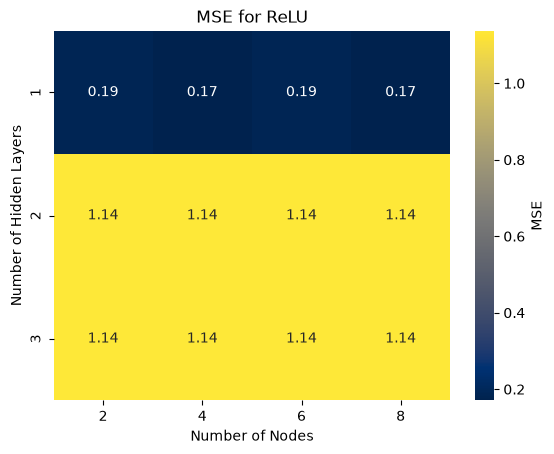

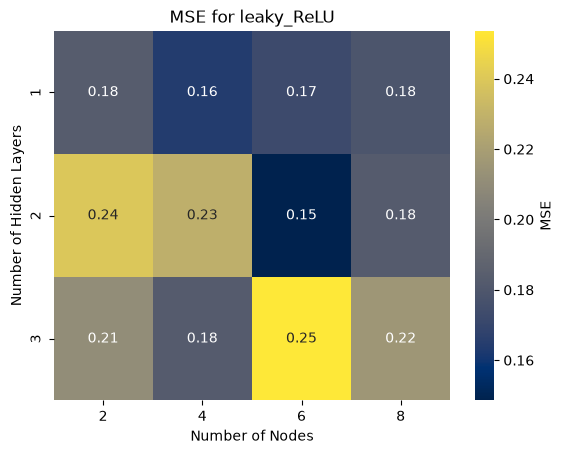

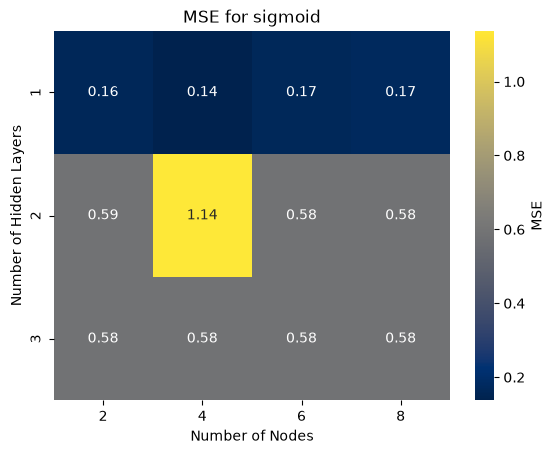

In [43]:
for i in range(len(functions)):
    sns.heatmap(MSEs[i], annot=True, fmt=".2f", xticklabels=number_of_nodes, yticklabels=number_of_hidden_layers, cmap = "cividis", cbar_kws={'label': 'MSE'})
    plt.title(f"MSE for {functions[i].__name__}")
    plt.xlabel("Number of Nodes")
    plt.ylabel("Number of Hidden Layers")
    plt.show()